The sinking of the Titanic is one of the most infamous shipwrecks in history.

On April 15, 1912, during her maiden voyage, the widely considered “unsinkable” RMS Titanic sank after colliding with an iceberg. Unfortunately, there weren’t enough lifeboats for everyone onboard, resulting in the death of 1502 out of 2224 passengers and crew.

Dataset https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv

•	survival	Survival	0 = No, 1 = Yes
•	pclass	Ticket class	1 = 1st, 2 = 2nd, 3 = 3rd
•	sex	Sex	
•	Age	Age in years	
•	sibsp	# of siblings / spouses aboard the Titanic	
•	parch	# of parents / children aboard the Titanic	
•	ticket	Ticket number	
•	fare	Passenger fare	
•	cabin	Cabin number	
•	embarked	Port of Embarkation	C = Cherbourg, Q = Queenstown, S = Southampton


# Load Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.rcParams['figure.figsize'] = [6, 3]
plt.rcParams['figure.dpi'] = 80

In [2]:
titanic = sns.load_dataset('titanic')

In [3]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
cols = titanic.columns
cols

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [5]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


# Heatmap

In [7]:
plt.style.use('ggplot')

In [8]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

<AxesSubplot:>

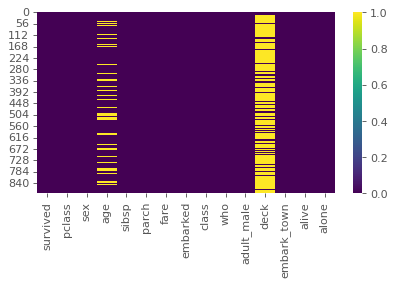

In [9]:
sns.heatmap(titanic.isnull(), cmap = 'viridis', cbar = True)

In [10]:
corrmat = titanic.corr()
corrmat

,survived,pclass,age,sibsp,parch,fare,adult_male,alone
survived,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307,-0.557080,-0.203367
pclass,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500,0.094035,0.135207
age,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067,0.280328,0.198270
sibsp,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651,-0.253586,-0.584471
parch,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225,-0.349943,-0.583398
fare,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000,-0.182024,-0.271832
adult_male,-0.557080,0.094035,0.280328,-0.253586,-0.349943,-0.182024,1.000000,0.404744
alone,-0.203367,0.135207,0.198270,-0.584471,-0.583398,-0.271832,0.404744,1.000000


<AxesSubplot:>

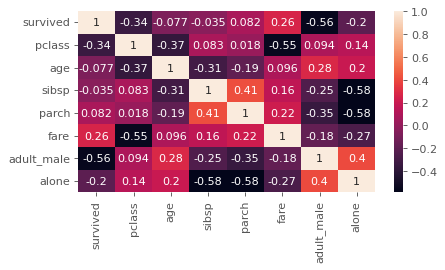

In [11]:
sns.heatmap(corrmat, annot=True)

Correlation Matrix and Heatmap is not suitable for Categorical data, so we will ignore



In [12]:
print(list(cols))

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning
/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning
/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning
/opt/conda/lib/python3.7/site-packages/seaborn

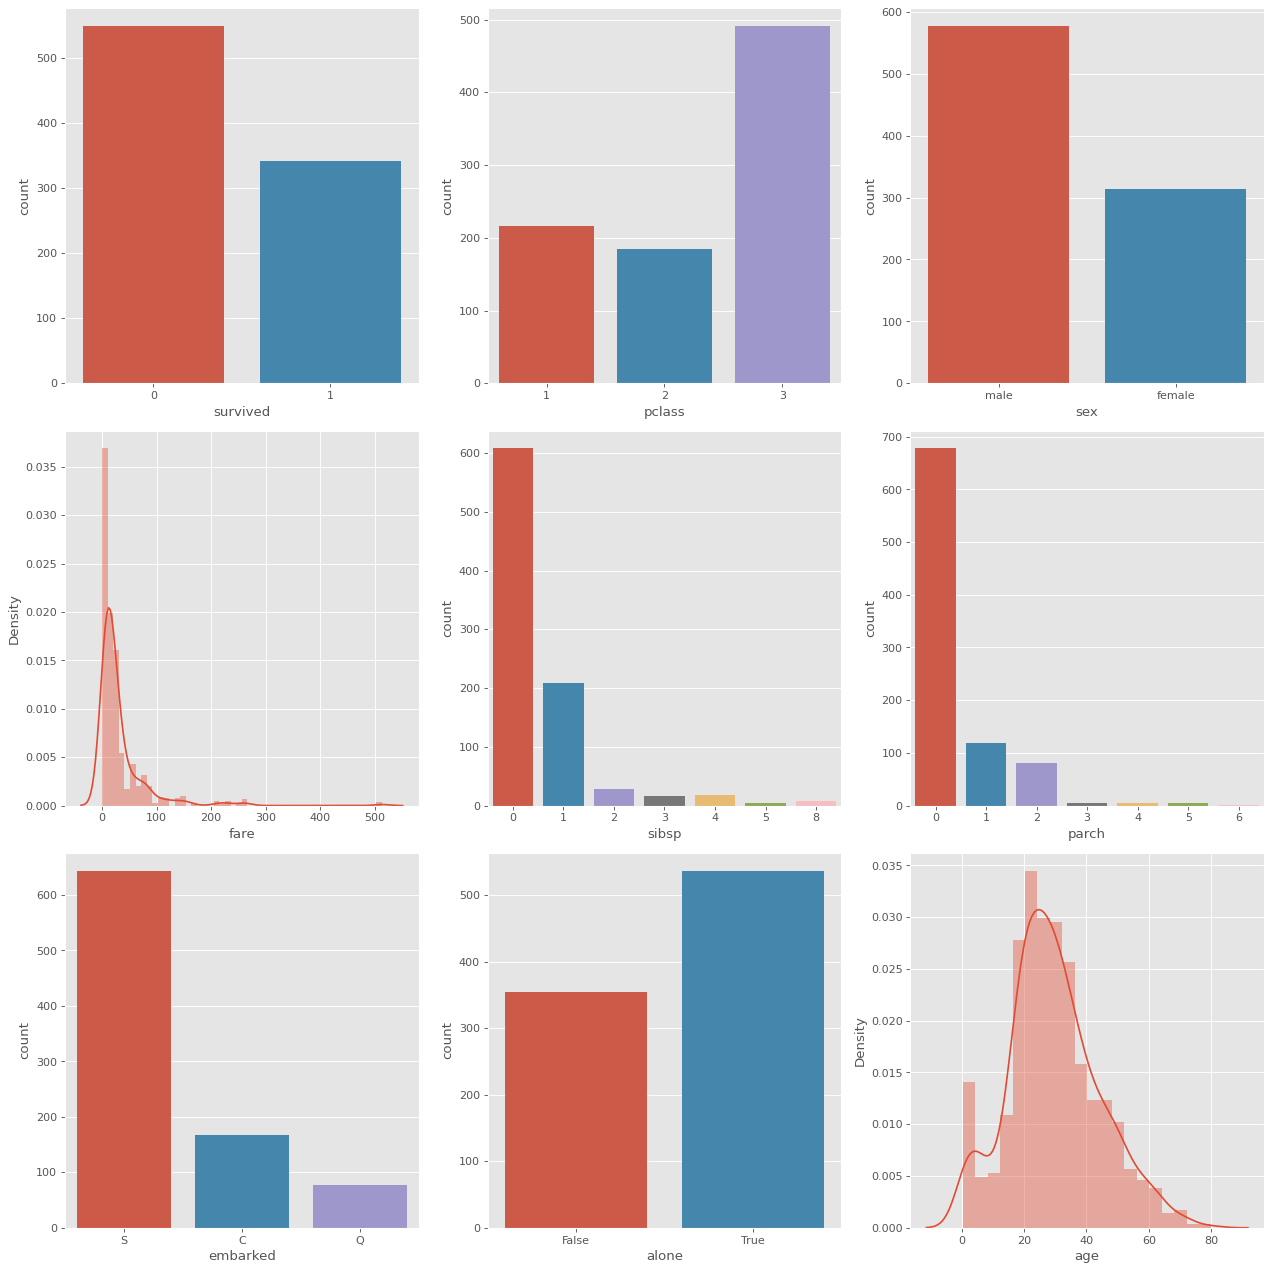

In [13]:
fig, ax = plt.subplots(3, 3, figsize = (16, 16))
sns.countplot('survived', data = titanic, ax = ax[0][0])
sns.countplot('pclass', data = titanic, ax = ax[0][1])
sns.countplot('sex', data = titanic, ax = ax[0][2])
sns.countplot('sibsp', data = titanic, ax = ax[1][1])
sns.countplot('parch', data = titanic, ax = ax[1][2])
sns.countplot('embarked', data = titanic, ax = ax[2][0])
sns.countplot('alone', data = titanic, ax = ax[2][1])
#sns.countplot('who', data = titanic, ax = ax[2][2])

sns.distplot(titanic['fare'], kde=True, ax = ax[1][0])
sns.distplot(titanic['age'], kde=True, ax = ax[2][2])


plt.tight_layout()



Survived

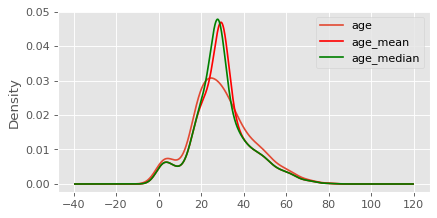

In [14]:
mean_age=titanic['age'].mean()
titanic['age_mean']=titanic['age'].fillna(mean_age)

median_age=titanic['age'].median()
titanic['age_median']=titanic['age'].fillna(median_age)

#titanic.info()

fig=plt.figure()
ax = fig.add_subplot(111)
titanic['age'].plot(kind='kde', ax=ax)
titanic['age_mean'].plot(kind='kde', ax=ax, color="red")
titanic['age_median'].plot(kind='kde', ax=ax, color="green")
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc="best")

age_variance = titanic['age'].var()
age_mean_variance = titanic['age_mean'].var()
age_median_variance = titanic['age_median'].var()


> **19.8% of the age values are missing.
> 136 3rd class are missing out of 491 that is 27.6%
> 22 2nd class are missing out of 184 that is 12%
> 30 1st class are missing out of 216 that is 14%
> 
> **Plotting the distribution after imputing with mean and median values of age, age_mean seems to be a better choice to use for ongoing EDA.**
> **

<AxesSubplot:>

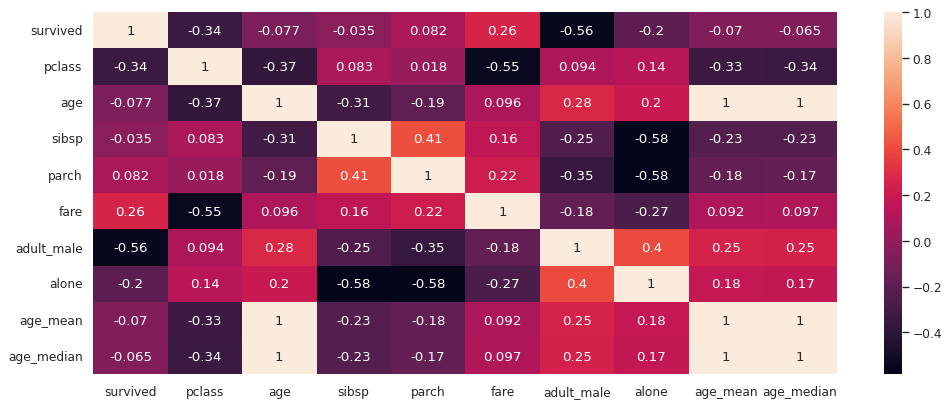

In [15]:
corrmat = titanic.corr()
corrmat
sns.set(rc = {'figure.figsize':(15,6)})

sns.heatmap(corrmat, annot=True)


<AxesSubplot:>

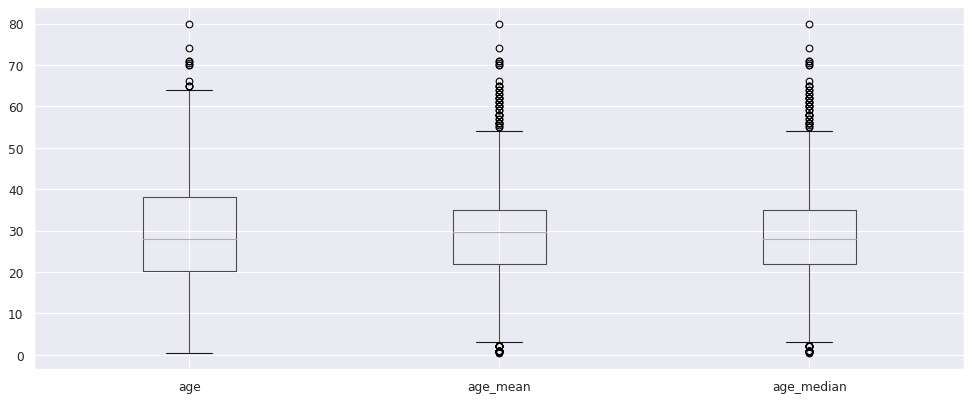

In [16]:
titanic[['age', 'age_mean', 'age_median']].boxplot()

/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


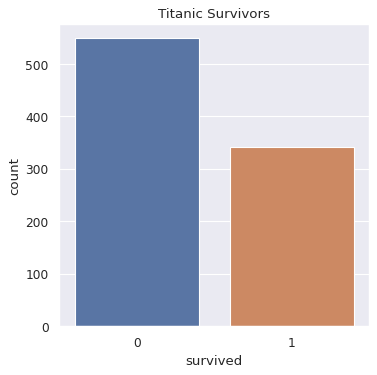

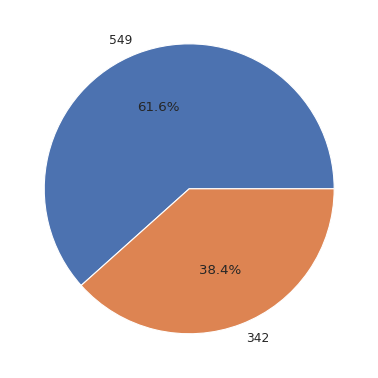

In [17]:
titanic['survived'].value_counts()

plt.figure(figsize=[5,5])

sns.countplot('survived', data=titanic)
plt.title('Titanic Survivors')
plt.show()

plt.pie(titanic['survived'].value_counts(), autopct = '%1.1f%%', labels = titanic['survived'].value_counts())
plt.show()

/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


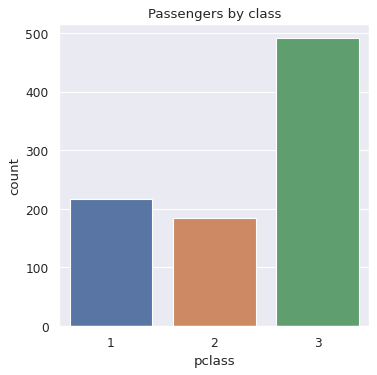

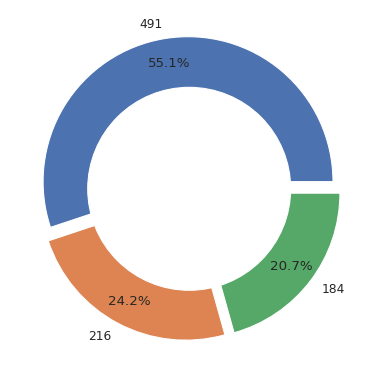

In [18]:
plt.figure(figsize=[5,5])

sns.countplot('pclass', data=titanic)
plt.title('Passengers by class')

plt.show()

explode = (0.05, 0.05, 0.05)
plt.pie(titanic['pclass'].value_counts(), autopct = '%1.1f%%', labels = titanic['pclass'].value_counts(), pctdistance=0.83, explode=explode)
# draw circle
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
  
# Adding Circle in Pie chart
fig.gca().add_artist(centre_circle)
plt.show()

In [19]:
titanic['pclass'].value_counts()

3    491
1    216
2    184
Name: pclass, dtype: int64

/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


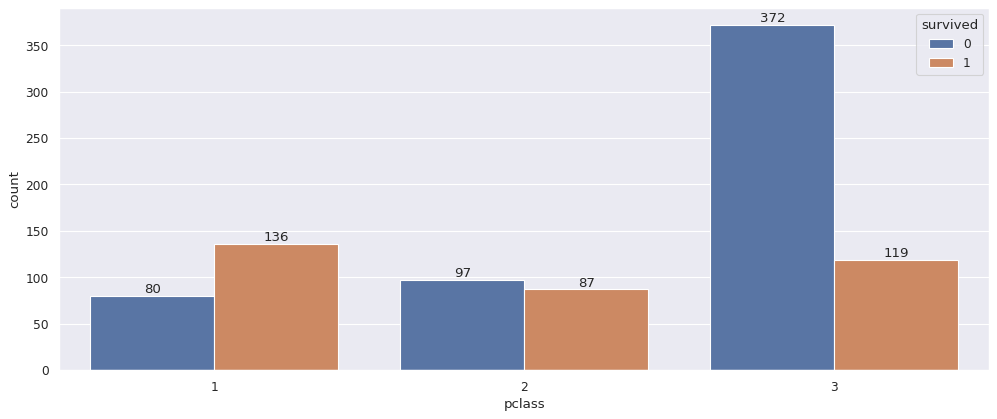

In [20]:
pclass_survived = titanic.groupby(['pclass', 'survived'])['survived'].count()
ax = sns.countplot('pclass', data=titanic, hue = 'survived')
for container in ax.containers:
    ax.bar_label(container)


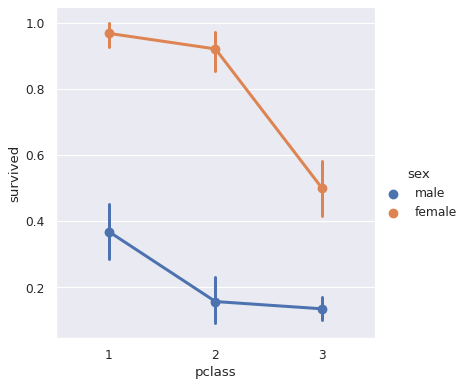

In [21]:
g = sns.catplot(x='pclass', y='survived', kind='point', data=titanic, hue='sex', legend=True)
ax = g.facet_axis(0, 0)

for c in ax.containers:
    ax.bar_label(c)

In [22]:
titanic['sex'].value_counts()

male      577
female    314
Name: sex, dtype: int64

/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


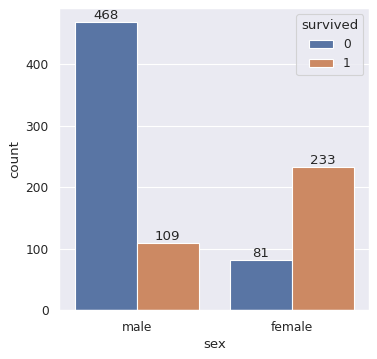

In [23]:
plt.figure(figsize=[5,5])

sex_survived = titanic.groupby(['sex', 'survived'])['survived'].count()
ax = sns.countplot('sex', data=titanic, hue = 'survived')
for container in ax.containers:
    ax.bar_label(container)

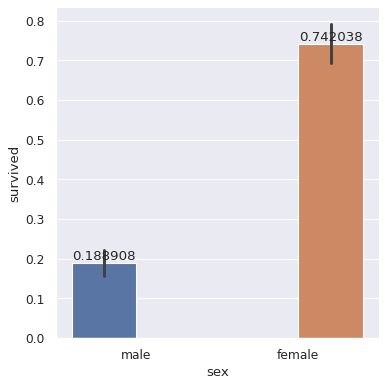

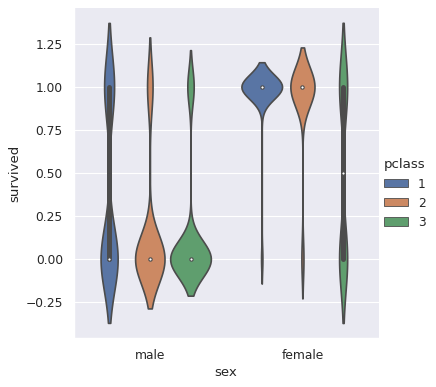

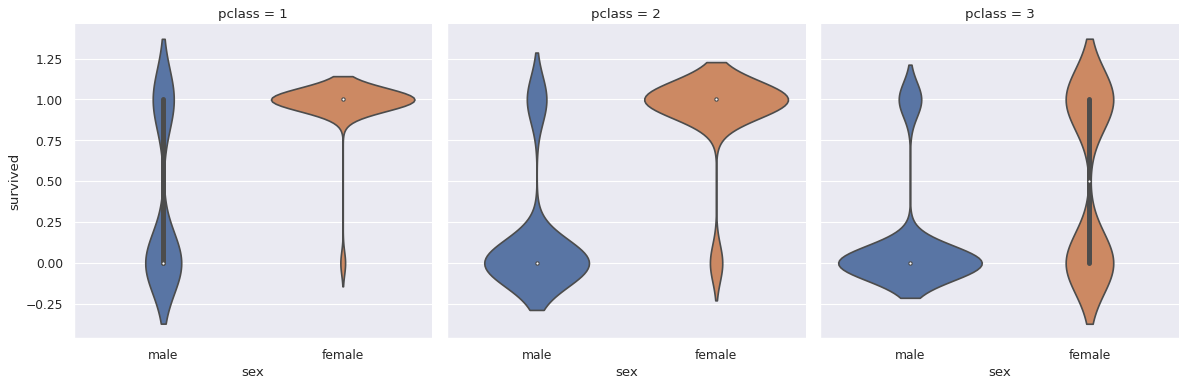

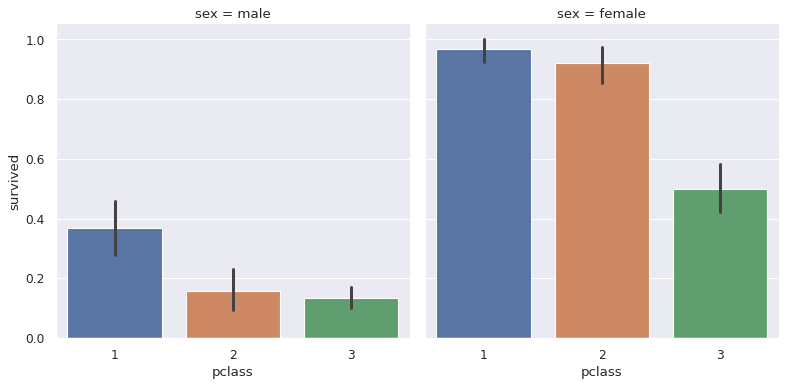

In [24]:
g = sns.catplot(x='sex', y='survived', kind='bar', data=titanic, hue='sex', legend=True)
ax = g.facet_axis(0, 0)

for c in ax.containers:
    ax.bar_label(c)

sns.catplot(x='sex', y='survived', kind='violin', data=titanic, hue='pclass', legend=True)

sns.catplot(x='sex', y='survived', kind='violin', data=titanic, col='pclass', legend=True)



g = sns.catplot(x='pclass', y='survived', kind='bar', data=titanic, col='sex', legend=True)



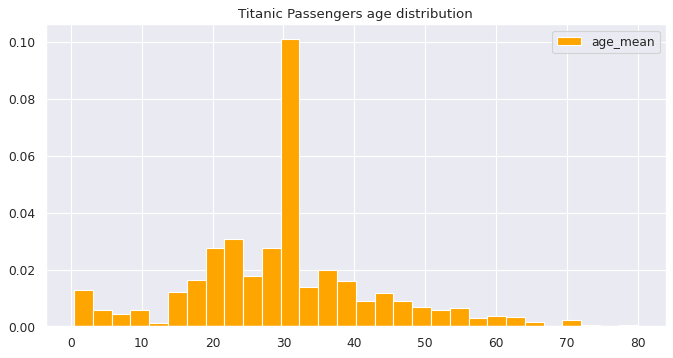

In [25]:
titanic['age_mean'].hist(bins=30, density=True, color='orange', figsize=(10, 5), legend=True)
plt.title('Titanic Passengers age distribution')
plt.show()

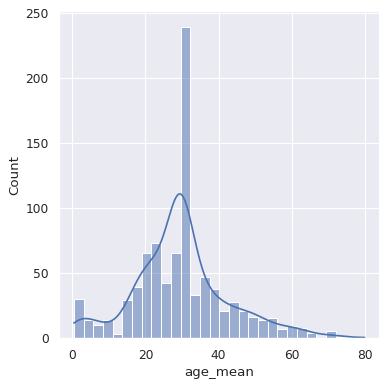

In [26]:
sns.displot(titanic['age_mean'], kde=True)


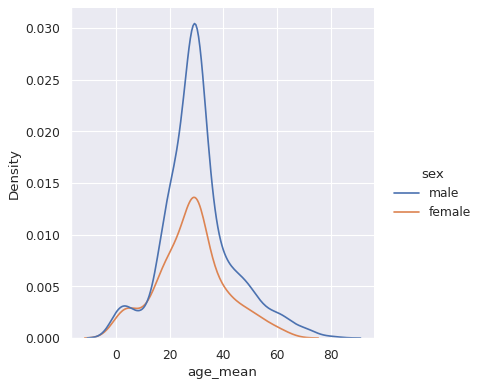

In [27]:
sns.displot(data=titanic, x='age_mean', hue='sex', kind='kde')


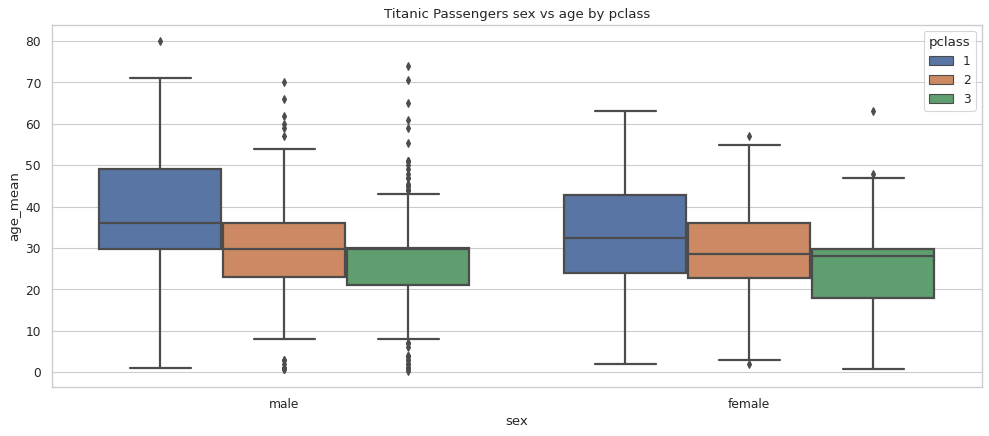

In [28]:
sns.set_theme(style="whitegrid")
sns.boxplot(data=titanic, x='sex', y='age_mean', hue='pclass', linewidth = 2)
plt.title('Titanic Passengers sex vs age by pclass')
plt.show()

<AxesSubplot:xlabel='who', ylabel='survived'>

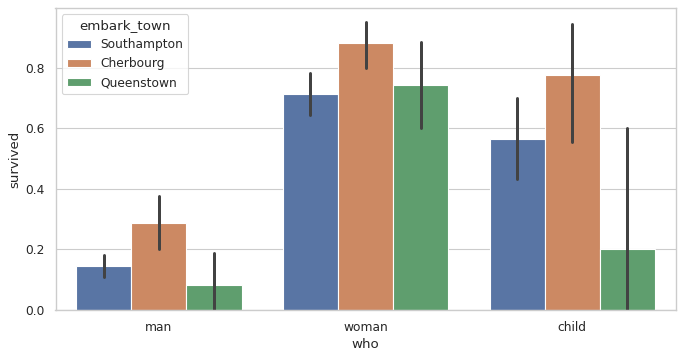

In [29]:
plt.figure(figsize=[10,5])

sns.barplot(data=titanic, x='who', y='survived', hue='embark_town')